# Fit five kinetic models and compare bank projection

**Question:** Which fitted kinetic forms preserve both the batch response and bank projection for this authored case?

Level: 2. Prerequisites: Level 1: Read a flotation bank as a kinetic response. Reading time: 30 minutes.

## Objectives

Run OreFlow's bounded nonlinear fits, inspect parameter bounds and residuals, and compare each fitted bank prediction with the engine's exact rate-distributed reference.

## Setup

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

The OreFlow pipeline is imported from `data-pipeline/`; this notebook never installs packages.

For the level 2 02-flotation lesson, record the pinned versions before analysis so the environment behind its tables and figures can be reconstructed.

In [1]:
# Import analysis tools and record their exact versions.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resolve the local pipeline from the repository-relative layout.
repo = Path("../../../").resolve()
sys.path.insert(0, str(repo / "data-pipeline"))
for package in ("numpy", "scipy", "pandas", "matplotlib", "nbclient", "nbformat", "ipykernel"):
    print(package, importlib.metadata.version(package))


numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Data

Owner: OreFlow authors; nominal Cu-Mo scenario and generated kinetic record in `data/derived/cases/copper_molybdenum.json`, MIT project licence. The response is simulated, not measured plant data. Repository: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Method

The virtual batch data are a mixture of first-order particle-class responses. OreFlow fits first-order, Kelsall, Klimpel, gamma and stretched-exponential forms with bounded Levenberg–Marquardt. It then projects each model through a bank; `kinetic_record` is the production entry point. Fit quality and bank projection are distinct checks.

Call the production fitter on a solved case. This executes all five OreFlow model implementations.

In [2]:
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
from pipeline.engine.kinetics import kinetic_record

# Solve once and use the pipeline's kinetic fitting routine.
case = next(item for item in CASES if item.id == "copper_molybdenum")
result = simulate(case.ore, case.plant, case.nominal)
fits = kinetic_record(
    result.flotation, result.ore, case.nominal.rougher_cells, result.metrics["rougher_recovery_pct"]
)
print("status:", fits["status"], "| fitted models:", len(fits.get("models", [])))


status: computed | fitted models: 5


Compare RMSE, convergence and bound status; a parameter at its limit is not silently treated as an interior optimum.

In [3]:
# Compare RMSE, convergence and bound status; a parameter at its limit is not silently treated as an
# interior optimum.
summary = pd.DataFrame(
    [
        {
            "model": m["id"],
            "RMSE (points)": m["rmse_pct"],
            "converged": m["converged"],
            "at bound": ", ".join(m["at_bound"]) or "no",
        }
        for m in fits["models"]
    ]
)
display(summary.set_index("model").round(4))


,RMSE (points),converged,at bound
model,,,
first_order,1.6397,True,no
kelsall,0.0283,True,no
klimpel,0.3976,True,no
gamma,0.1464,True,no
stretched_exponential,0.6667,True,no


Overlay the fitted curves on the virtual batch observations using the same time points.

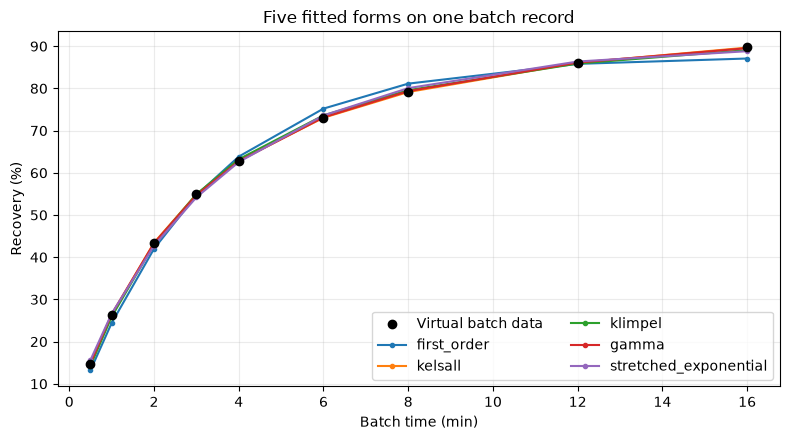

In [4]:
# Overlay the fitted curves on the virtual batch observations using the same time points.
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(
    fits["times_min"],
    fits["batch_recovery_pct"],
    color="black",
    zorder=4,
    label="Virtual batch data",
)
for model in fits["models"]:
    ax.plot(fits["times_min"], model["fitted_pct"], marker=".", label=model["id"])
ax.set(
    xlabel="Batch time (min)", ylabel="Recovery (%)", title="Five fitted forms on one batch record"
)
ax.grid(True, alpha=0.25)
ax.legend(ncol=2)
fig.tight_layout()


Figure 13 in the level 2 02 flotation lesson reports outputs of independently solved operating points. For figure 13 in level 2 02 flotation, each mark is a separate model evaluation at its stated setting. For figure 13 in level 2 02 flotation, check recovery, size and energy against the contract limits. The line in figure 13 only guides comparison.

Compare lumped bank projections against the exact distributed-rate calculation, including behaviour beyond the final batch sample.

In [5]:
# Compare lumped bank projections against the exact distributed-rate calculation, including
# behaviour beyond the final batch sample.
projection = pd.DataFrame(
    [
        {
            "model": m["id"],
            "bank projection (%)": m["bank_projection_pct"],
            "error vs exact (points)": m["lumping_error_pct"],
            "ultimate gap (points)": m["ultimate_gap_pct"],
        }
        for m in fits["models"]
    ]
)
display(projection.round(3))
print("exact bank recovery (%):", fits["bank"]["exact_true_flotation_pct"])


,model,bank projection (%),error vs exact (points),ultimate gap (points)
0,first_order,87.393,-6.590,0.471
1,kelsall,92.662,-1.320,4.540
2,klimpel,92.665,-1.318,9.604
3,gamma,92.951,-1.032,7.034
4,stretched_exponential,90.005,-3.977,1.724


exact bank recovery (%): 93.9822410776771


In the level 2 02 flotation case, the 0.8× nominal throughput run changes fresh-feed rate while holding the other controls at their authored nominal point. For the level 2 02 flotation case at 0.8× feed, recovery, product size and energy are coupled outputs of the resolved circuit model.

In [6]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_molybdenum")
factor = 0.8
point_0_8 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_0_8 = simulate(case.ore, case.plant, point_0_8)
print("throughput (t/h):", round(point_0_8.throughput_tph, 2))
print("recovery (%):", round(response_0_8.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_0_8.metrics["p80_um"], 2))


throughput (t/h): 512.0
recovery (%): 94.842
product P80 (µm): 150.0


In the level 2 02 flotation case, the 0.9× nominal throughput run changes fresh-feed rate while holding the other controls at their authored nominal point. For the level 2 02 flotation case at 0.9× feed, recovery, product size and energy are coupled outputs of the resolved circuit model.

In [7]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_molybdenum")
factor = 0.9
point_0_9 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_0_9 = simulate(case.ore, case.plant, point_0_9)
print("throughput (t/h):", round(point_0_9.throughput_tph, 2))
print("recovery (%):", round(response_0_9.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_0_9.metrics["p80_um"], 2))


throughput (t/h): 576.0
recovery (%): 94.143
product P80 (µm): 150.0


In the level 2 02 flotation case, the 1.0× nominal throughput run changes fresh-feed rate while holding the other controls at their authored nominal point. For the level 2 02 flotation case at 1.0× feed, recovery, product size and energy are coupled outputs of the resolved circuit model.

In [8]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_molybdenum")
factor = 1.0
point_1_0 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_0 = simulate(case.ore, case.plant, point_1_0)
print("throughput (t/h):", round(point_1_0.throughput_tph, 2))
print("recovery (%):", round(response_1_0.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_0.metrics["p80_um"], 2))


throughput (t/h): 640.0
recovery (%): 93.447
product P80 (µm): 150.0


In the level 2 02 flotation case, the 1.1× nominal throughput run changes fresh-feed rate while holding the other controls at their authored nominal point. For the level 2 02 flotation case at 1.1× feed, recovery, product size and energy are coupled outputs of the resolved circuit model.

In [9]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_molybdenum")
factor = 1.1
point_1_1 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_1 = simulate(case.ore, case.plant, point_1_1)
print("throughput (t/h):", round(point_1_1.throughput_tph, 2))
print("recovery (%):", round(response_1_1.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_1.metrics["p80_um"], 2))


throughput (t/h): 704.0
recovery (%): 92.753
product P80 (µm): 150.0


In the level 2 02 flotation case, the 1.2× nominal throughput run changes fresh-feed rate while holding the other controls at their authored nominal point. For the level 2 02 flotation case at 1.2× feed, recovery, product size and energy are coupled outputs of the resolved circuit model.

In [10]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_molybdenum")
factor = 1.2
point_1_2 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_2 = simulate(case.ore, case.plant, point_1_2)
print("throughput (t/h):", round(point_1_2.throughput_tph, 2))
print("recovery (%):", round(response_1_2.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_2.metrics["p80_um"], 2))


throughput (t/h): 768.0
recovery (%): 89.749
product P80 (µm): 167.43


In the level 2 02 flotation lesson, plot reading 1 considers in this level 2 02 flotation plot, compare recovery with product P80 across the controlled throughput changes. In the level 2 02 flotation lesson, plot reading 2 considers the two axes keep unlike units separate, so interpret each change as a response of this authored case rather than as an empirical plant trend. In the level 2 02 flotation lesson, plot reading 3 considers the nominal point is included as a reference for the neighboring settings. In the level 2 02 flotation lesson, plot reading 4 considers for fit five kinetic models and compare bank projection, the plotted points come from separate engine evaluations, and the lines only guide the eye between tested settings.

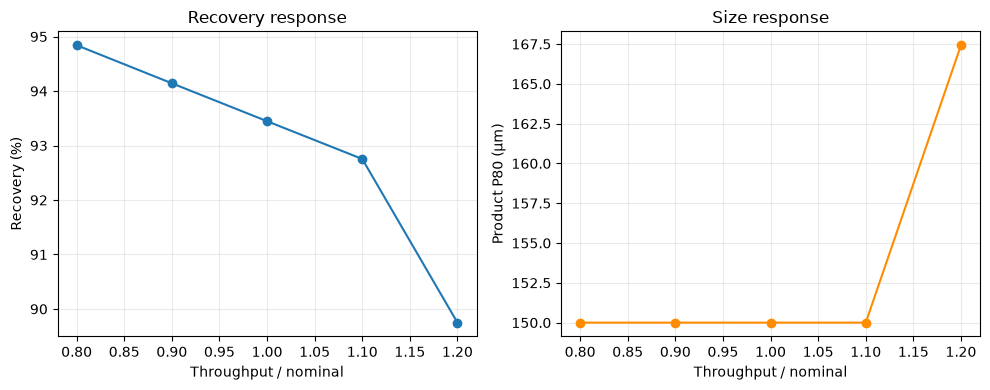

In [11]:
# Plot responses from the independently solved operating points.
import matplotlib.pyplot as plt

factors = [0.8, 0.9, 1.0, 1.1, 1.2]
runs = [response_0_8, response_0_9, response_1_0, response_1_1, response_1_2]
rates = [run.metrics["recovery_pct"] for run in runs]
sizes = [run.metrics["p80_um"] for run in runs]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(factors, rates, marker="o")
axes[0].set(xlabel="Throughput / nominal", ylabel="Recovery (%)", title="Recovery response")
axes[1].plot(factors, sizes, marker="o", color="darkorange")
axes[1].set(xlabel="Throughput / nominal", ylabel="Product P80 (µm)", title="Size response")
for axis in axes:
    axis.grid(True, alpha=0.25)
fig.tight_layout()


Figure 27 in the level 2 02 flotation lesson reports outputs of independently solved operating points. For figure 27 in level 2 02 flotation, each mark is a separate model evaluation at its stated setting. For figure 27 in level 2 02 flotation, check recovery, size and energy against the contract limits. The line in figure 27 only guides comparison.

At level 2 in 02 flotation, interpretation 1 is that flotation recovery is conditional on the solids and mineral distribution delivered by grinding, the declared floatability parameters, collector response and available residence time. At level 2 in 02 flotation, interpretation 2 is that a higher feed rate changes the time available per unit mass even when cell volume is unchanged. At level 2 in 02 flotation, interpretation 3 is that the model represents that coupling through the bank calculation. At level 2 in 02 flotation, interpretation 4 is that it does not animate individual particles or infer froth behaviour from an image. At level 2 in 02 flotation, interpretation 5 is that compare valuable-mineral recovery with concentrate grade and water recovery, because a recovery increase can also carry more gangue or water. At level 2 in 02 flotation, interpretation 6 is that kinetic forms such as first-order, fast/slow and distributed-rate models can fit similar batch curves while giving different bank projections. At level 2 in 02 flotation, interpretation 7 is that a synthetic exact-rate reference allows internal approximation error to be measured, but it is not a laboratory test. At level 2 in 02 flotation, interpretation 8 is that transfer to a plant requires timed samples, reagent records, air rate, cell geometry and an independently held-out campaign. At level 2 in 02 flotation, extension 1 shows that a defensible kinetic comparison keeps the batch times, fitted ultimate recovery and bank residence assumptions fixed across candidate forms. At level 2 in 02 flotation, extension 2 shows that report residual structure as well as RMSE, since late-time samples can dominate a squared-error fit while early recovery controls a short bank. At level 2 in 02 flotation, extension 3 shows that do not interpret the fitted parameters as unique mineral constants when the observations are generated by the same simulator.

## Results

**Answer:** In this level 2 02 flotation lesson, the executed circuit reports recovery of 93.9822410776771 percent at the first controlled throughput setting for Fit five kinetic models and compare bank projection.

The curves show approximation quality on the virtual batch record. Bank error compares lumped predictions with the engine's exact distribution reference. A low batch RMSE does not guarantee a low bank-projection error; neither is field validation.

## Summary

You executed the product's fitter and separated fit residual, projection error and extrapolation gap. The whole comparison remains within an engine-generated virtual test.

## References

- https://doi.org/10.1016/0301-7516(81)90019-3
- https://doi.org/10.1016/0301-7516(81)90019-3
- https://doi.org/10.1016/0301-7516(81)90019-3